In [52]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
df = pd.read_csv(r"C:\Users\murmu\Desktop\MCCAI\NLP_C\spam (1).csv", encoding='ISO-8859-1')
df

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN
...,...,...,...,...,...
5567,spam,This is the 2nd time we have tried 2 contact u...,NaN,NaN,NaN
5568,ham,Will Ì_ b going to esplanade fr home?,NaN,NaN,NaN
5569,ham,"Pity, * was in mood for that. So...any other s...",NaN,NaN,NaN
5570,ham,The guy did some bitching but I acted like i'd...,NaN,NaN,NaN


In [7]:
print(df.shape)
print(df.size)

(5572, 5)
27860


In [6]:
df.isnull().sum()

v1               0
v2               0
Unnamed: 2    5522
Unnamed: 3    5560
Unnamed: 4    5566
dtype: int64

In [8]:
# drop the column
df.drop(['Unnamed: 2','Unnamed: 3','Unnamed: 4'], axis = 1, inplace=True)
df.head()

,v1,v2
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [9]:
df.columns = ['labels', 'messages']
df.head(3)

,labels,messages
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...


In [11]:
df.labels.unique()

array(['ham', 'spam'], dtype=object)

In [48]:
df['b_labels'] = df['labels'].map({'ham' : 0, 'spam' : 1})
df

,labels,messages,b_labels
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0
...,...,...,...
5567,spam,This is the 2nd time we have tried 2 contact u...,1
5568,ham,Will Ì_ b going to esplanade fr home?,0
5569,ham,"Pity, * was in mood for that. So...any other s...",0
5570,ham,The guy did some bitching but I acted like i'd...,0


In [12]:
# ip/op creation : 
ip = df.messages
op = df['b_labels'].values

In [13]:
ip.head()

0    Go until jurong point, crazy.. Available only ...
1                        Ok lar... Joking wif u oni...
2    Free entry in 2 a wkly comp to win FA Cup fina...
3    U dun say so early hor... U c already then say...
4    Nah I don't think he goes to usf, he lives aro...
Name: messages, dtype: object

In [15]:
op

array([0, 0, 1, ..., 0, 0, 0], dtype=int64)

In [24]:
# Train test split
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(ip,op,test_size=0.35)

In [25]:
# it convert text into numeric vector based on word importance
from sklearn.feature_extraction.text import TfidfVectorizer
tfidf = TfidfVectorizer()
x_train = tfidf.fit_transform(x_train)
x_test = tfidf.transform(x_test)

In [27]:
# model train
from sklearn.naive_bayes import MultinomialNB
algo = MultinomialNB()
algo.fit(x_train, y_train)

MultinomialNB()

In [31]:
print('Training Score : ', algo.score(x_train,y_train))
print('Testing Score : ', algo.score(x_test,y_test))

Training Score :  0.9704501518917427
Testing Score :  0.9630958482829318


In [33]:
pred = algo.predict(x_test)
pred

array([0, 0, 0, ..., 0, 0, 1], dtype=int64)

In [34]:
from sklearn.metrics import accuracy_score, recall_score, f1_score, precision_score
acc = accuracy_score(y_test,pred)
recall = recall_score(y_test,pred)
f1 = f1_score(y_test,pred)
precision = precision_score(y_test,pred)
print("Accuracy : ", acc)
print("Recall score : ", recall)
print("f1 score : ", f1)
print("Precision score : ", precision)

Accuracy :  0.9630958482829318
Recall score :  0.7037037037037037
f1 score :  0.8260869565217391
Precision score :  1.0


## WordCloud : 
<pre>
A word cloud is a visual representation of text data where frequently used words appear larger and less frequent words appear smaller
</pre>

In [35]:
# to import wordcloud
from wordcloud import WordCloud

ModuleNotFoundError: No module named 'wordcloud'

In [38]:
# to install wordcloud
# !pip3 install wordcloud

In [39]:
# to import wordcloud
from wordcloud import WordCloud

In [49]:
# Visulize
def visualize(label):
    words = ''
    for msg in df[df.labels==label]['messages']:
        msg = msg.lower()
        words += msg
    wordCloud=WordCloud(width=600, height=400).generate(words)
    plt.imshow(wordCloud)
    plt.axis('off')
    plt.show()

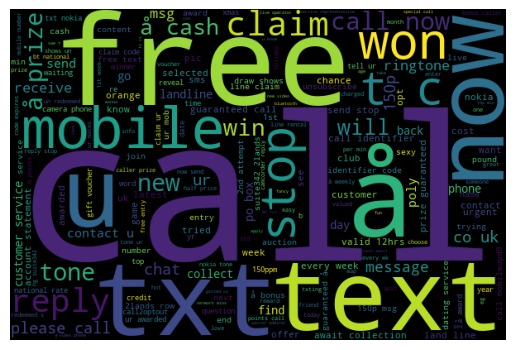

In [53]:
visualize('spam')

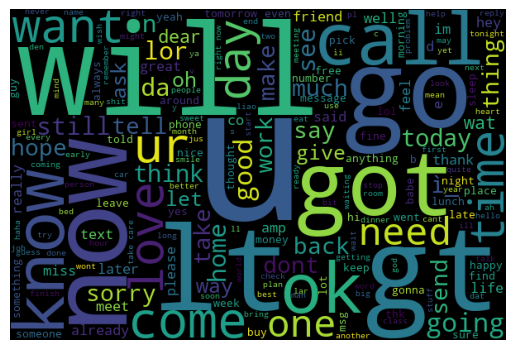

In [54]:
visualize('ham')

## Fetch_20newsgroup : 

In [1]:
from sklearn.datasets import fetch_20newsgroups

In [ ]:
news = fetch_20newsgroups()